In [4]:
import numpy as np
import os 
import h5py
import pandas as pd
import matplotlib.pyplot as plt
from scipy.io import loadmat
from scipy.signal import savgol_filter
from sklearn.preprocessing import MinMaxScaler
import warnings
from scipy import stats
import seaborn as sns
import scipy.ndimage
import scipy.stats as stats
from scipy.ndimage import gaussian_filter1d
from scipy.stats import ranksums
from numba import jit
import matplotlib as mpl
import random
import pickle

In [5]:
#Remove right and top spines from plots (personal preference)
mpl.rcParams['axes.spines.right'] = False
mpl.rcParams['axes.spines.top'] = False
mpl.rcParams['axes.spines.left'] = False
mpl.rcParams['axes.spines.bottom'] = False

In [6]:
mouse_ID = 'IS-2-1L'
date = '2026-07-01'

In [7]:
stat = np.load('/Volumes/Akhil Data/Akhil/ProcessedData/{}/{}/suite2p/plane0/stat.npy'.format(mouse_ID, date), allow_pickle=True)
ops = np.load('/Volumes/Akhil Data/Akhil/ProcessedData/{}/{}/suite2p/plane0/ops.npy'.format(mouse_ID, date), allow_pickle=True)
lines = np.load('/Volumes/Akhil Data/Akhil/RawData/HX-12-3L/align to atlas/blue_lines_matrix-2.npy')

## Plot lines on max projection

In [8]:
ops_dict = ops.item()

[]

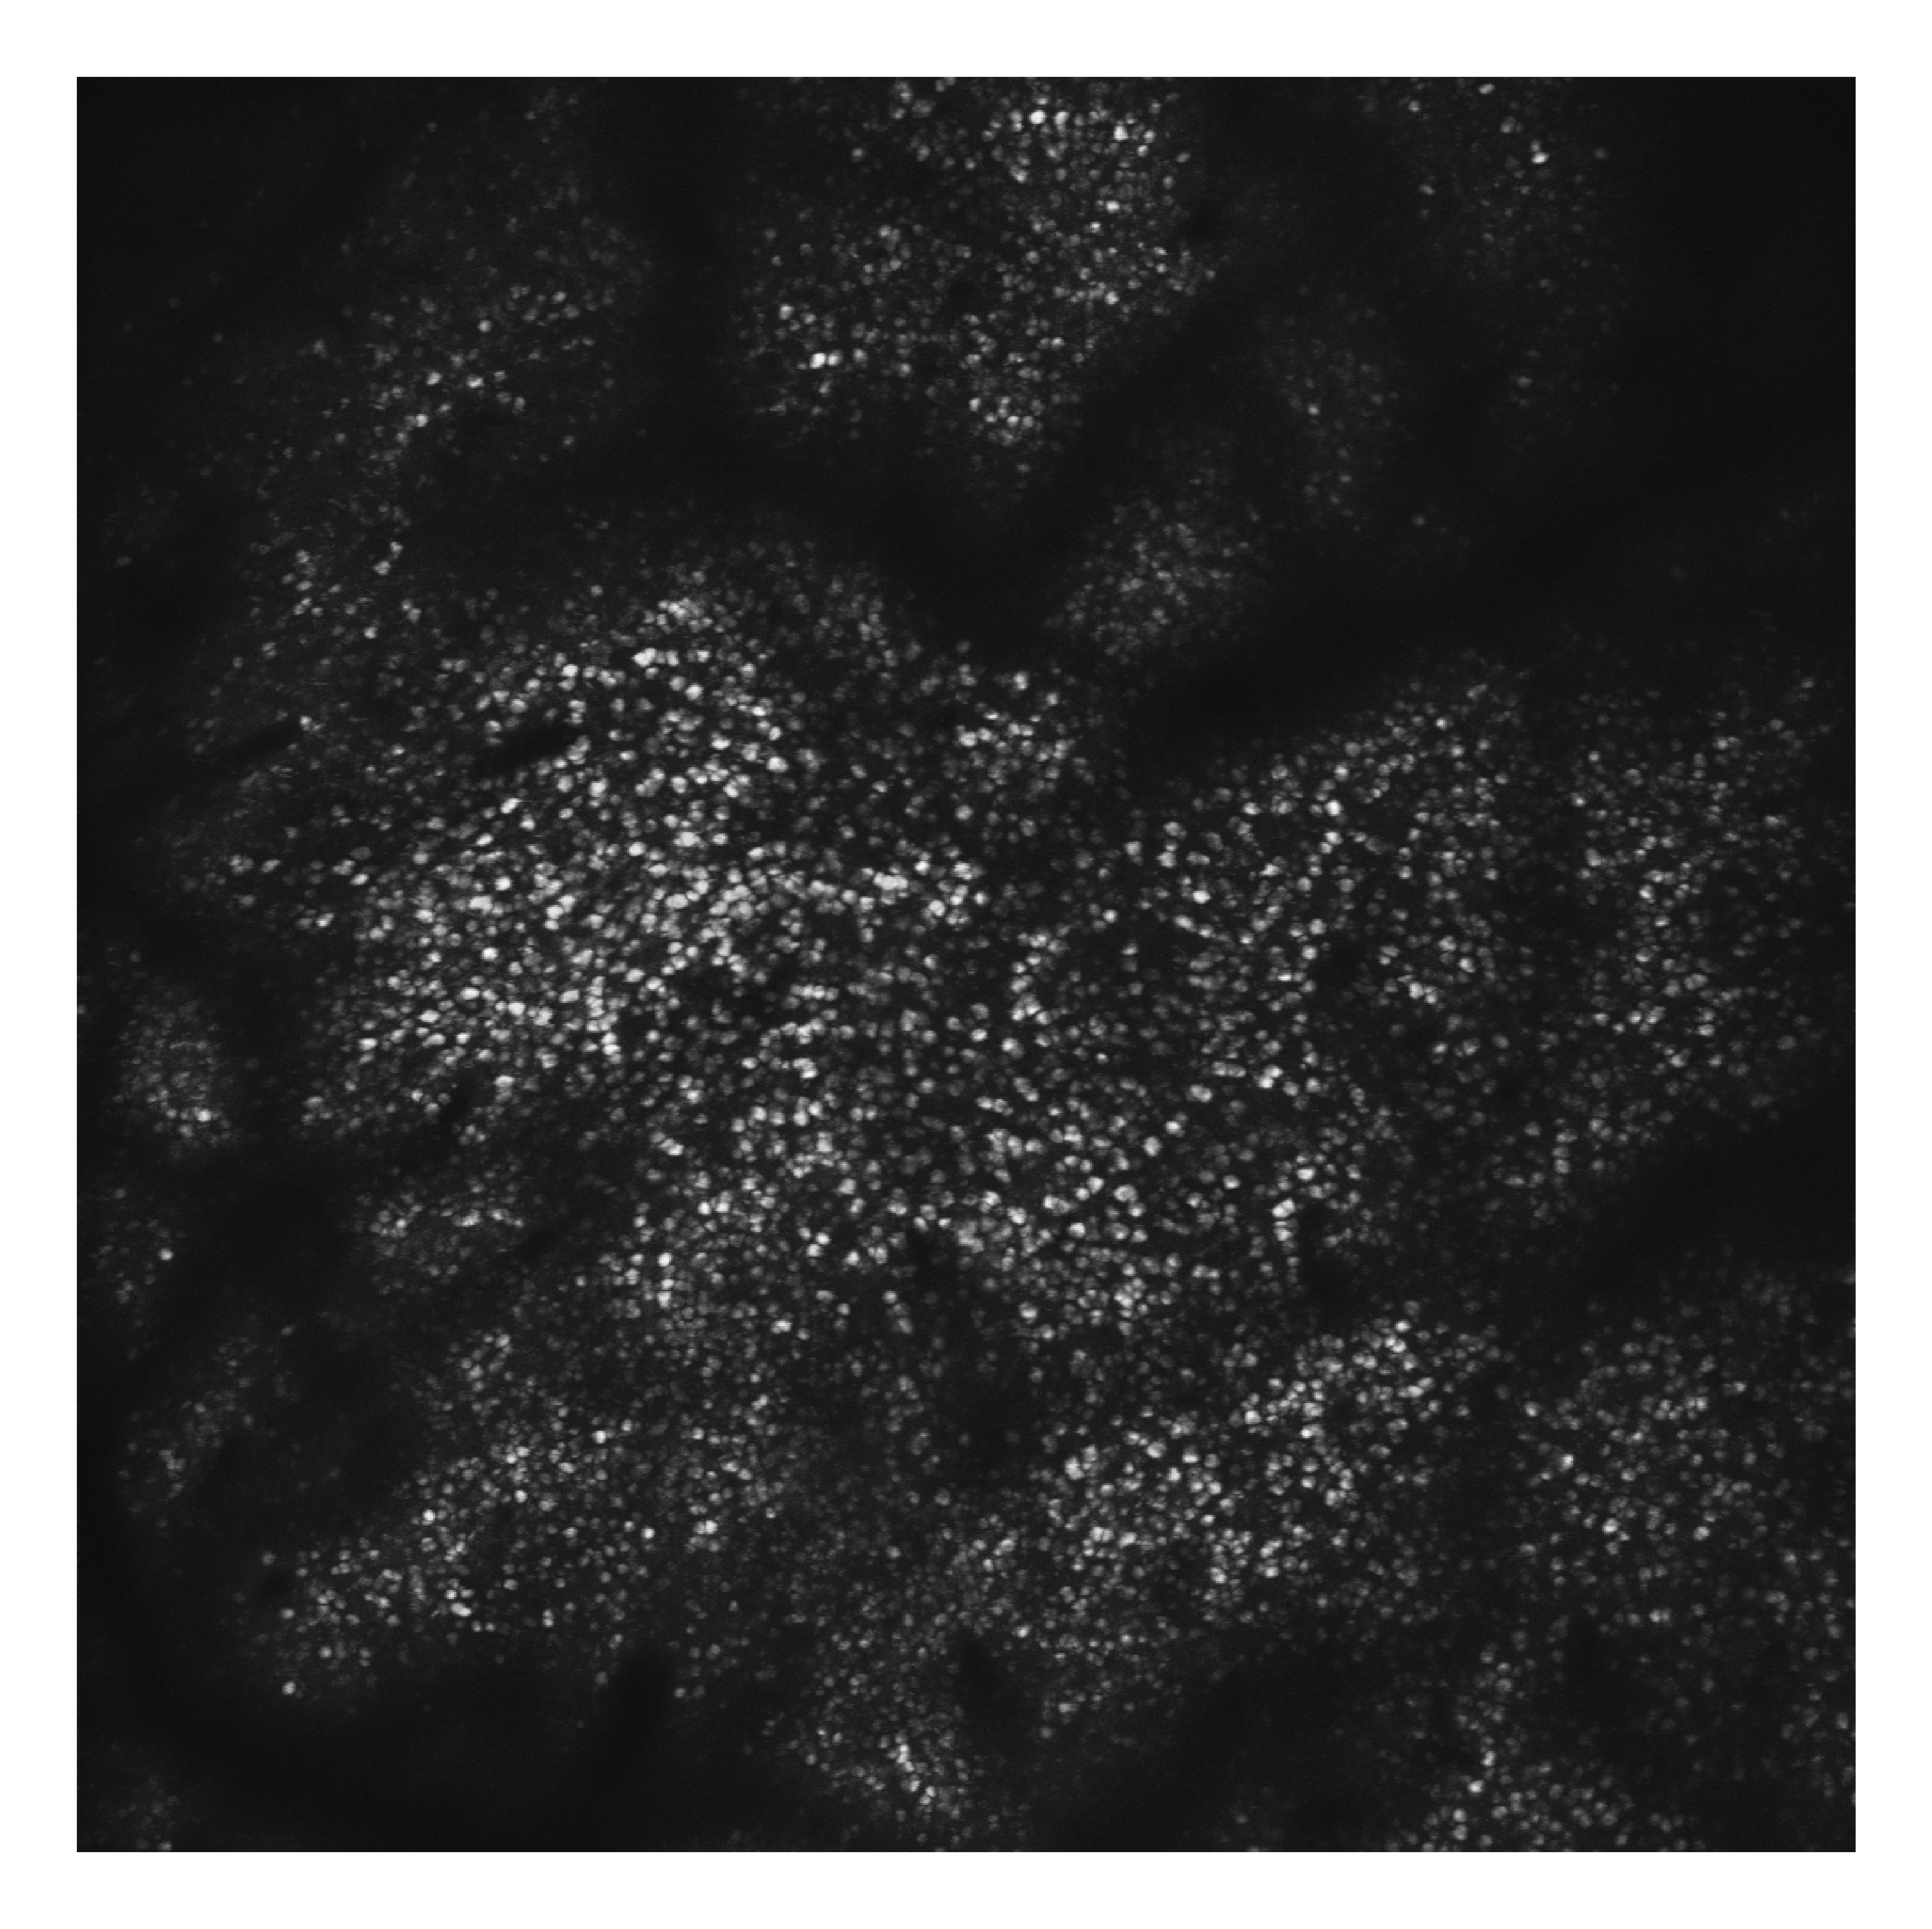

In [9]:
#Remove right and top spines from plots (personal preference)
mpl.rcParams['axes.spines.right'] = False
mpl.rcParams['axes.spines.top'] = False
mpl.rcParams['axes.spines.left'] = False
mpl.rcParams['axes.spines.bottom'] = False

fig, axs = plt.subplots(figsize=(3, 3), dpi = 1600)

axs.imshow(ops_dict['max_proj'], alpha=0.95, cmap='gist_gray')
#axs.imshow(lines[:1006, :1002], alpha=0.25)
axs.set_xticks([])
axs.set_yticks([])

## Segment the image into different anatomical regions

In [24]:
import numpy as np
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt

def extract_region(image_array, lower_bound, upper_bound):
    """
    Extract and fill a region based on the color bounds.
    
    Parameters:
    - image_array: The image as a numpy array.
    - lower_bound: Lower RGB bounds for the color.
    - upper_bound: Upper RGB bounds for the color.
    
    Returns:
    - filled_matrix: A binary matrix where the region is filled (1) and the rest is 0.
    """
    # Create a mask for the specified color range
    mask = np.all((image_array >= lower_bound) & (image_array <= upper_bound), axis=-1)
    
    # Create a binary matrix for the region where matching pixels are 1
    filled_matrix = mask.astype(np.uint8)
    
    return filled_matrix

def categorize_rois_by_region(stat, regions):
    """
    Categorize the ROIs by region and store the ROI indices in a dictionary as NumPy arrays.
    
    Parameters:
    - stat: A list of dictionaries with 'xpix' and 'ypix' arrays representing ROIs.
    - regions: A dictionary where the keys are region names and the values are binary matrices.
    
    Returns:
    - roi_indices_by_region: A dictionary where each key is a region name and the value is an array of ROI indices.
    """
    # Initialize a dictionary to store ROI indices by region
    roi_indices_by_region = {region_name: [] for region_name in regions.keys()}
    
    # Loop through each region
    for region_name, region_matrix in regions.items():
        
        # Loop through each ROI and check if any part of it is within the filled region
        for idx, roi in enumerate(stat):
            xpix = roi['xpix']
            ypix = roi['ypix']

            # Check if any pixel in the ROI falls within the region
            if np.any(region_matrix[ypix, xpix] == 1):
                # Add the ROI index to the corresponding region in the dictionary
                roi_indices_by_region[region_name].append(idx)
    
    # Convert lists to NumPy arrays
    for region_name in roi_indices_by_region:
        roi_indices_by_region[region_name] = np.array(roi_indices_by_region[region_name])
    
    return roi_indices_by_region

def plot_rois_in_region(stat, regions, colors):
    """
    Plot ROIs that fall within specified regions, with each region's ROIs in the color of that region.
    
    Parameters:
    - stat: A list of dictionaries with 'xpix' and 'ypix' arrays representing ROIs.
    - regions: A dictionary where the keys are region names and the values are binary matrices.
    - colors: A dictionary where the keys are region names and the values are the colors for plotting.
    """
    plt.figure(figsize=(10, 10), dpi=100)
    plt.gca().set_frame_on(False)
    # Loop through each region and its corresponding color
    for region_name, region_matrix in regions.items():
        color = colors[region_name]
        
        # Loop through each ROI and check if any part of it is within the filled region
        for roi in stat:
            xpix = roi['xpix']
            ypix = roi['ypix']

            # Check if any pixel in the ROI falls within the region
            if np.any(region_matrix[ypix, xpix] == 1):
                # Plot the ROI pixels in the color of the region
                plt.plot(xpix, ypix, 'o', markersize=.1, color=color, alpha=0.5)  # Separate marker and color
    #plt.imshow(ops_dict['max_proj'], alpha=1, cmap='gist_gray')
    plt.xlim([0, 1024])
    plt.ylim([0, 1024])
    plt.xticks([])
    plt.yticks([])
    plt.gca().invert_yaxis()  # Invert the y-axis to match image coordinates
    #plt.title("ROIs within Regions")
    plt.show()

In [31]:
# Load the filled image
filled_image_path = "/Volumes/Akhil Data/Akhil/RawData/{}/cortical borders/{}/cortical_borders_filled.png".format(mouse_ID, date)   
filled_image = Image.open(filled_image_path)

# Resize and convert to numpy array
filled_image = filled_image.resize((1024, 1024))
filled_image_array = np.array(filled_image.convert("RGB"))

# Define narrow color bounds for different regions
regions_bounds = {
    "PPC":   ([0, 120, 0],     [80, 255, 80]),      # green
    "AM":    ([120, 0, 0],     [255, 80, 80]),      # red
    "PM":    ([200, 200, 0],   [255, 255, 100]),    # yellow
    "V1":    ([0, 0, 100],     [100, 100, 255]),    # blue
    "RSC":   ([230, 145, 0],   [255, 149, 30]),     # orange
    "RL":    ([0, 0, 0],       [50, 50, 50]),       # black
    "SMc": ([230, 230, 230], [255, 255, 255]),    # intentionally-white region
}

# Extract regions based on defined color bounds
regions = {}
for region_name, (lower_bound, upper_bound) in regions_bounds.items():
    regions[region_name] = extract_region(filled_image_array, np.array(lower_bound), np.array(upper_bound))

# Define the color for each region
colors = {
    "PPC": 'g',      # Green
    "AM": 'tomato',  # Red
    "PM": 'y',       # Yellow
    "V1": 'skyblue', # Blue
    "RSC": 'orange', # Orange
    "RL": 'k',        # Black
    'SMc': 'gray'
}

In [32]:
roi_indices_by_region = categorize_rois_by_region(stat, regions)

In [33]:
# Print the number of neurons in each region
for region, indices in roi_indices_by_region.items():
    print(f"{region}: {len(indices)} neurons")

PPC: 1317 neurons
AM: 766 neurons
PM: 625 neurons
V1: 1761 neurons
RSC: 264 neurons
RL: 503 neurons
SMc: 315 neurons


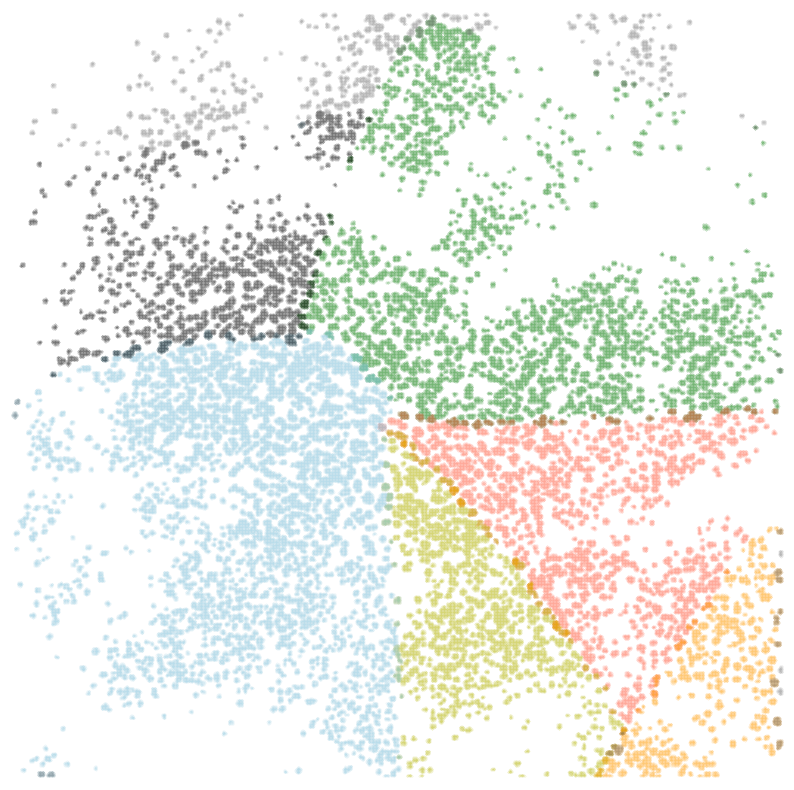

In [34]:
# Plot all ROIs in the corresponding colors
plot_rois_in_region(stat, regions, colors)

In [35]:
# Save to a pickle file
path = '/Volumes/Akhil Data/Akhil/ProcessedData/{}/{}/'.format(mouse_ID, date)
os.chdir(path)
with open('roi_indices_by_region.pkl', 'wb') as pickle_file:
    pickle.dump(roi_indices_by_region, pickle_file)

/var/folders/tb/ct0s7r6j0q90l_p7cs6hshr80000gn/T/ipykernel_14630/2017719661.py:15: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(regions, color='black')  # First set them all to black


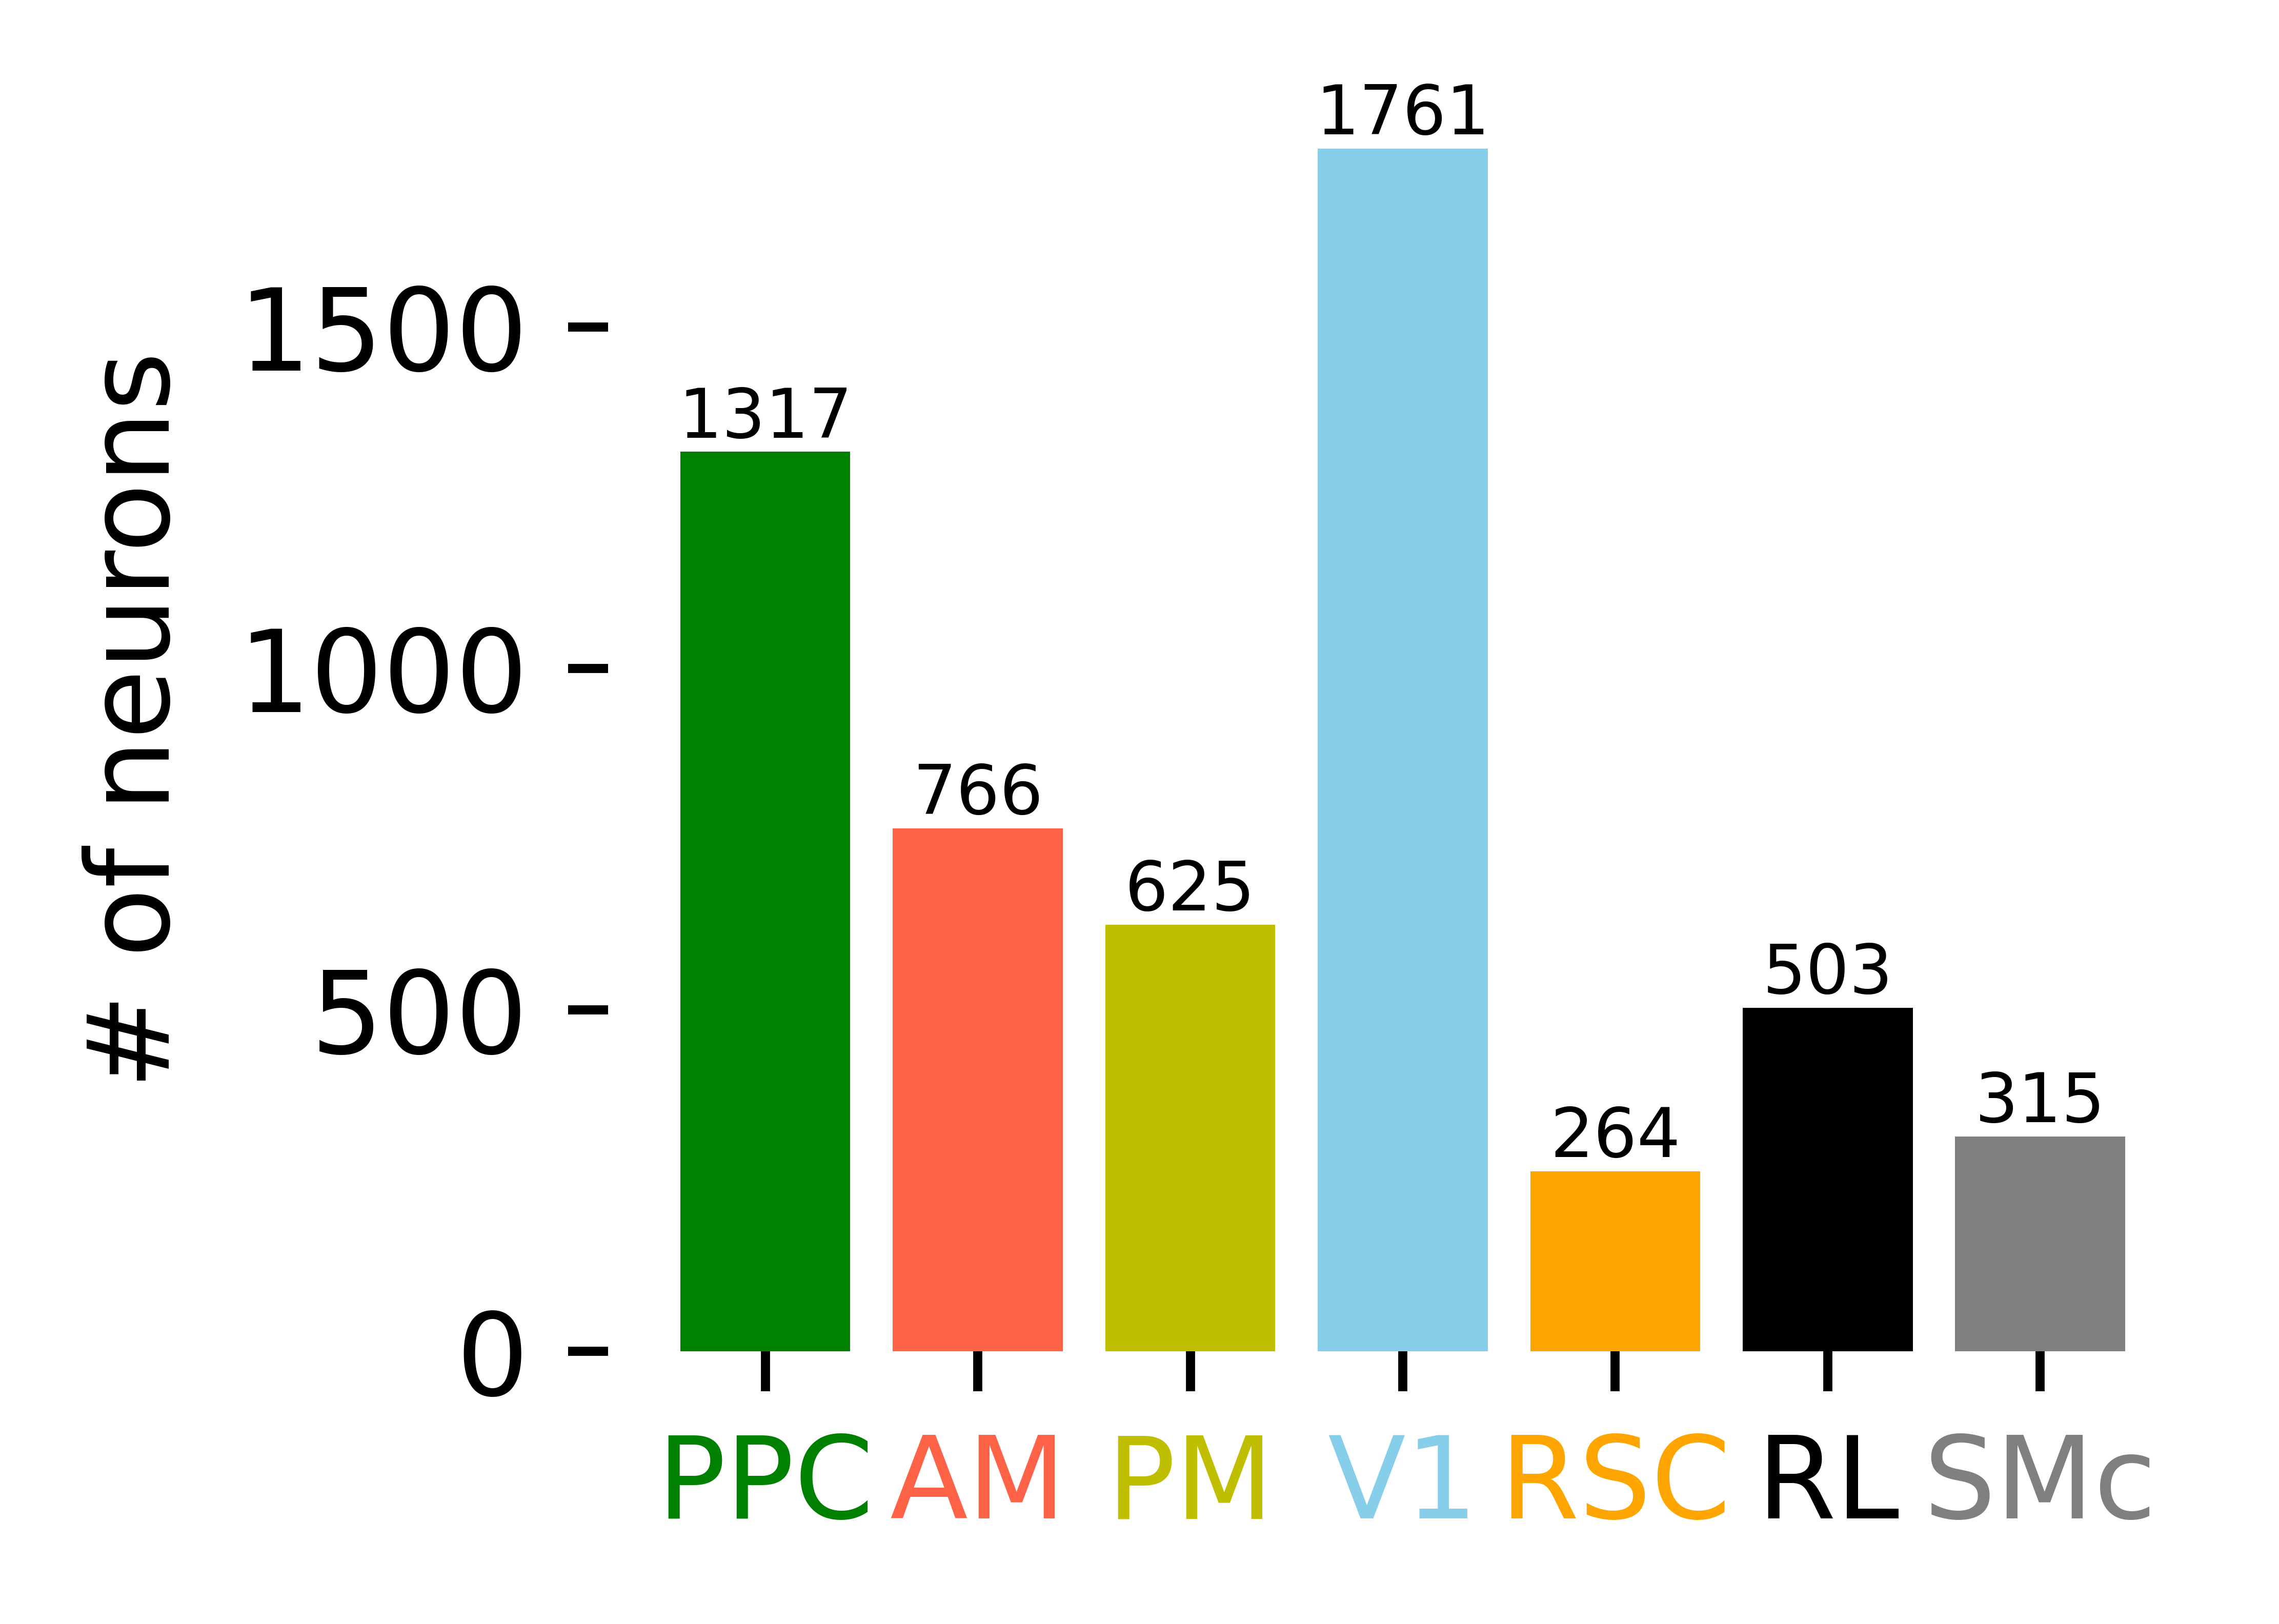

In [36]:
# Create data for the bar plot
regions = list(roi_indices_by_region.keys())
neuron_counts = [len(roi_indices_by_region[region]) for region in regions]

# Create the bar plot
plt.figure(figsize=(2.5, 2), dpi=1600)
bars = plt.bar(regions, neuron_counts, color=[colors[region] for region in regions])

# Customize the plot
plt.ylabel('# of neurons')
#plt.title('Neuron Count by Region')

# Color the x-tick labels according to each region's color
ax = plt.gca()
ax.set_xticklabels(regions, color='black')  # First set them all to black
for ticklabel, region in zip(ax.get_xticklabels(), regions):
    ticklabel.set_color(colors[region])

# Remove top and right spines
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Add value labels on top of each bar
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height,
             f'{int(height)}',
             ha='center', va='bottom', fontsize=6)

save_path = '/Users/akhilbandi/Documents/Portfolio/code_projects/VACANT analysis/Data Alignment/AVC_analysis/figures'
#plt.savefig(os.path.join(save_path, f'large_FOV_number_of_neurons.svg'), format='svg', dpi=1600, bbox_inches='tight')

plt.show()